# Validación estadística de la superioridad

## Protocolo común
- **Mismas particiones, misma semilla (2026), mismo preprocesamiento** para ATER y para los 7 benchmarks (3 tradicionales y 4 de Machine Learning).
- **Validación anidada temporal:** el bucle externo son los folds 1 a 4 de la validación de ventana creciente (purga de 48 h); dentro de cada uno, Optuna ajusta los hiperparámetros de ATER **solo con los folds anteriores**.
- **Prueba única:** enero 2025 – octubre 2026, 653 días. ATER se entrena con los mismos datos y los mismos expertos que los benchmarks y pronostica en línea.
- **Unidad de comparación:** la pérdida diaria (MSE de las 24 horas de cada día), que es la unidad en que se emite el pronóstico.
- **Pruebas (ruta de series de tiempo del Cuadro 3):** (1) **Model Confidence Set** con todos los modelos, (2) **Giacomini-White** condicional, (3) **Diebold-Mariano con corrección HLN**, y como complemento **Wilcoxon** de rangos con signo. Ajuste de **Holm-Bonferroni** sobre las 21 comparaciones (3 pruebas × 7 benchmarks). IC por **bootstrap estacionario** (bloque medio de 7 días) y tamaños del efecto (δ de Cliff y d de Cohen).

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)
R = "../resultados/"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
ORIG = "ATER (modelo original)"
COL = {"Persistencia (misma hora de ayer)": "#9AA5A0", "Estacional (misma hora semana pasada)": "#B8C2BD", "Promedio por hora y día": "#D5DBD8",
       "Ridge (lineal)": "#5B7F96", "Random forest (relativo)": "#1F5A3A", "XGBoost (relativo)": "#C8892B",
       "Híbrido Ridge + XGBoost (residuo relativo)": "#8E4B7A", ORIG: "#C0392B"}

In [2]:
an = pd.read_csv(R + "orig_validacion_anidada.csv"); af = pd.read_csv(R + "orig_validacion_anidada_folds.csv")
print("Validación anidada temporal (bucle externo = folds 1 a 4), media ± desviación estándar:")
an.assign(MSE=lambda d: d.MSE_media.round(0).astype(int).astype(str) + " ± " + d.MSE_de.round(0).astype(int).astype(str),
          MAPE=lambda d: d.MAPE_media.round(2).astype(str) + " ± " + d.MAPE_de.round(2).astype(str))[["modelo", "MSE", "MAPE"]]

Validación anidada temporal (bucle externo = folds 1 a 4), media ± desviación estándar:


,modelo,MSE,MAPE
0,ATER (modelo original),2097 ± 821,2.76 ± 0.42
1,Híbrido Ridge + XGBoost (residuo relativo),2210 ± 759,2.93 ± 0.36
2,Random forest (relativo),2240 ± 806,2.87 ± 0.37
3,XGBoost (relativo),2247 ± 793,2.87 ± 0.39
4,Ridge (lineal),2542 ± 856,3.22 ± 0.42
5,Persistencia (misma hora de ayer),5711 ± 951,4.66 ± 0.31
6,Estacional (misma hora semana pasada),6797 ± 2323,5.22 ± 0.68
7,Promedio por hora y día,12107 ± 5856,7.43 ± 1.89


In [3]:
print("MSE por fold externo:"); af.pivot(index="modelo", columns="fold", values="MSE").round(0)

MSE por fold externo:


fold,1,2,3,4
modelo,,,,
ATER (modelo original),1809.0,1349.0,1967.0,3264.0
Estacional (misma hora semana pasada),5707.0,4286.0,7548.0,9648.0
Híbrido Ridge + XGBoost (residuo relativo),1932.0,1515.0,2106.0,3285.0
Persistencia (misma hora de ayer),5019.0,5035.0,5747.0,7044.0
Promedio por hora y día,4985.0,9823.0,15648.0,17973.0
Random forest (relativo),1935.0,1500.0,2146.0,3380.0
Ridge (lineal),2190.0,1739.0,2500.0,3738.0
XGBoost (relativo),2039.0,1492.0,2095.0,3364.0


In [4]:
tp = pd.read_csv(R + "orig_prueba.csv")
tp[["modelo", "MSE", "RMSE", "MAE", "MAPE", "AUC_pico", "CSI", "mejora_vs_persistencia_%", "entrenamiento_s", "inferencia_s"]].round(3)

,modelo,MSE,RMSE,MAE,MAPE,AUC_pico,CSI,mejora_vs_persistencia_%,entrenamiento_s,inferencia_s
0,ATER (modelo original),2256.092,47.498,32.585,2.435,0.975,0.835,65.400,32.597,0.777
1,Random forest (relativo),2347.073,48.447,33.979,2.543,0.974,0.827,64.005,29.366,0.402
2,XGBoost (relativo),2416.944,49.162,34.087,2.548,0.973,0.826,62.934,2.191,0.062
3,Híbrido Ridge + XGBoost (residuo relativo),3075.115,55.454,42.428,3.083,0.971,0.770,52.840,0.662,0.068
4,Ridge (lineal),3568.599,59.738,46.473,3.383,0.966,0.743,45.272,0.145,0.026
5,Persistencia (misma hora de ayer),6520.590,80.750,57.992,4.345,0.926,0.716,0.000,0.000,0.000
6,Estacional (misma hora semana pasada),8436.854,91.852,66.633,5.002,0.906,0.681,-29.388,0.000,0.000
7,Promedio por hora y día,53601.852,231.521,203.080,14.444,0.831,0.000,-722.040,0.000,0.909


## Supuestos
- **Diebold-Mariano** necesita que la serie de diferencias de pérdida sea estacionaria y usa una varianza HAC (7 rezagos) por la autocorrelación; se verifica con la prueba ADF.
- **Giacomini-White** se plantea con esquema de ventana fija (los expertos se entrenan una vez, como pide la prueba) e instrumentos $h_{t-1}=(1, d_{t-1})$; solo exige momentos finitos de $d_t$.
- **MCS** usa bootstrap estacionario (bloque medio de 7 días), así que tolera dependencia temporal.
- **Wilcoxon** supone simetría y no corrige la autocorrelación: se usa como prueba complementaria, no como una de las tres principales.

In [5]:
adf = pd.read_csv(R + "orig_adf.csv"); adf.round(4)

,benchmark,ADF,p_ADF
0,Persistencia (misma hora de ayer),-3.9819,0.0015
1,Estacional (misma hora semana pasada),-6.6052,0.0000
2,Promedio por hora y día,-2.0273,0.2748
3,Ridge (lineal),-7.1889,0.0000
4,Random forest (relativo),-15.1359,0.0000
5,XGBoost (relativo),-20.3781,0.0000
6,Híbrido Ridge + XGBoost (residuo relativo),-6.0978,0.0000


 La serie de diferencias es estacionaria (ADF, p < 0,01) frente a todos los benchmarks excepto el promedio por hora y día (p = 0,27): esa comparación de Diebold-Mariano es menos confiable, pero la diferencia frente a ese modelo es de 96 % y las pruebas MCS y Giacomini-White no dependen de ese supuesto.

## Prueba 1: Model Confidence Set (Hansen, Lunde y Nason, 2011)

In [6]:
mcs = pd.read_csv(R + "orig_mcs.csv"); mcs

,modelo,p_MCS,en_conjunto_10pct
0,Persistencia (misma hora de ayer),0.0000,False
1,Estacional (misma hora semana pasada),0.0000,False
2,Ridge (lineal),0.0000,False
3,Promedio por hora y día,0.0000,False
4,Híbrido Ridge + XGBoost (residuo relativo),0.0000,False
5,XGBoost (relativo),0.0006,False
6,Random forest (relativo),0.0046,False
7,ATER (modelo original),1.0000,True


 Con $\alpha=0{,}10$ (la convención del MCS), **el conjunto de modelos superiores contiene solo a ATER**: los siete benchmarks se eliminan, el random forest relativo con p = 0,005 y el XGBoost relativo con p = 0,001.

## Pruebas 2 y 3 (y complementaria): Giacomini-White, Diebold-Mariano y Wilcoxon

In [7]:
pr = pd.read_csv(R + "orig_pruebas_hipotesis.csv")
print("Hipótesis nula de cada prueba: igual desempeño (pérdida diaria esperada igual) entre ATER y el benchmark.")
print("Comparaciones totales para el ajuste de Holm:", pr.n_comparaciones.iloc[0])
pr[["prueba", "benchmark", "supuestos", "estadistico", "p_crudo", "p_holm", "conclusion"]].round(5)

Hipótesis nula de cada prueba: igual desempeño (pérdida diaria esperada igual) entre ATER y el benchmark.
Comparaciones totales para el ajuste de Holm: 21


,prueba,benchmark,supuestos,estadistico,p_crudo,p_holm,conclusion
0,Diebold-Mariano (HLN),Persistencia (misma hora de ayer),serie de diferencias de pérdida estacionaria (ADF); varianza HAC con 7 rezagos,16.75053,0.00000,0.00000,ATER mejor (rechaza H0)
1,Giacomini-White condicional,Persistencia (misma hora de ayer),diferencias de pérdida con momentos finitos; esquema de ventana fija (expertos entrenados una vez),176.47729,0.00000,0.00000,ATER mejor (rechaza H0)
2,Wilcoxon de rangos con signo,Persistencia (misma hora de ayer),diferencias simétricas alrededor de la mediana; no corrige autocorrelación (complementaria),20721.00000,0.00000,0.00000,ATER mejor (rechaza H0)
3,Diebold-Mariano (HLN),Estacional (misma hora semana pasada),serie de diferencias de pérdida estacionaria (ADF); varianza HAC con 7 rezagos,9.98926,0.00000,0.00000,ATER mejor (rechaza H0)
4,Giacomini-White condicional,Estacional (misma hora semana pasada),diferencias de pérdida con momentos finitos; esquema de ventana fija (expertos entrenados una vez),171.13490,0.00000,0.00000,ATER mejor (rechaza H0)
5,Wilcoxon de rangos con signo,Estacional (misma hora semana pasada),diferencias simétricas alrededor de la mediana; no corrige autocorrelación (complementaria),18507.00000,0.00000,0.00000,ATER mejor (rechaza H0)
6,Diebold-Mariano (HLN),Promedio por hora y día,serie de diferencias de pérdida estacionaria (ADF); varianza HAC con 7 rezagos,11.08991,0.00000,0.00000,ATER mejor (rechaza H0)
7,Giacomini-White condicional,Promedio por hora y día,diferencias de pérdida con momentos finitos; esquema de ventana fija (expertos entrenados una vez),444.41921,0.00000,0.00000,ATER mejor (rechaza H0)
8,Wilcoxon de rangos con signo,Promedio por hora y día,diferencias simétricas alrededor de la mediana; no corrige autocorrelación (complementaria),1560.00000,0.00000,0.00000,ATER mejor (rechaza H0)
9,Diebold-Mariano (HLN),Ridge (lineal),serie de diferencias de pérdida estacionaria (ADF); varianza HAC con 7 rezagos,9.71606,0.00000,0.00000,ATER mejor (rechaza H0)


## Intervalos y tamaños del efecto

In [8]:
ef = pr.drop_duplicates("benchmark")[["benchmark", "mejora_MSE_pct", "IC95_lo", "IC95_hi", "dias_gana_ATER_pct", "delta_cliff_pareado", "magnitud_cliff_pareado", "delta_cliff", "magnitud_cliff", "d_cohen"]]
ef.round(3)

,benchmark,mejora_MSE_pct,IC95_lo,IC95_hi,dias_gana_ATER_pct,delta_cliff_pareado,magnitud_cliff_pareado,delta_cliff,magnitud_cliff,d_cohen
0,Persistencia (misma hora de ayer),65.400,60.560,69.710,83.308,0.666,grande,0.463,mediano,0.606
3,Estacional (misma hora semana pasada),73.259,69.124,77.180,81.011,0.620,grande,0.484,grande,0.571
6,Promedio por hora y día,95.791,94.428,96.780,97.397,0.948,grande,0.940,grande,1.063
9,Ridge (lineal),36.779,28.756,44.745,78.254,0.565,grande,0.407,mediano,0.460
12,Random forest (relativo),3.876,1.119,6.799,62.634,0.253,pequeño,0.073,despreciable,0.119
15,XGBoost (relativo),6.655,3.767,9.536,61.103,0.222,pequeño,0.068,despreciable,0.135
18,Híbrido Ridge + XGBoost (residuo relativo),26.634,18.663,34.679,74.732,0.495,grande,0.343,mediano,0.398


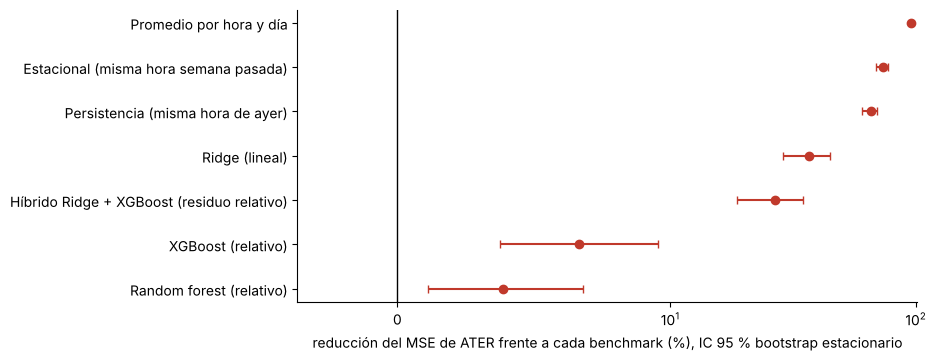

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8)); e = ef.sort_values("mejora_MSE_pct")
ax.errorbar(e.mejora_MSE_pct, e.benchmark, xerr=[e.mejora_MSE_pct - e.IC95_lo, e.IC95_hi - e.mejora_MSE_pct], fmt="o", color="#C0392B", capsize=3)
ax.axvline(0, color="k", lw=1); ax.set_xscale("symlog", linthresh=10); ax.set_xlabel("reducción del MSE de ATER frente a cada benchmark (%), IC 95 % bootstrap estacionario")
plt.show()

In [10]:
sem = pd.read_csv(R + "orig_semillas.csv"); print("Robustez ante la semilla de los expertos aleatorios (prueba):"); sem.round(1)

Robustez ante la semilla de los expertos aleatorios (prueba):


,semilla,MSE_ATER,MSE_Random forest (relativo),MSE_XGBoost (relativo),mejora_vs_RF_%
0,2026,2256.1,2347.1,2416.9,3.9
1,7,2265.8,2352.7,2434.5,3.7
2,42,2264.1,2350.7,2421.0,3.7
3,123,2259.7,2344.7,2423.4,3.6
4,999,2257.5,2349.2,2425.4,3.9


Meses en que ATER tiene menos MSE que el RF: 18 de 22
               MAPE_ATER  MAPE_RF    horas
tipo de día                               
festivo             3.34     3.72    768.0
fin de semana       2.69     2.84   4440.0
laboral             2.26     2.33  10464.0 

              MAPE_ATER  MAPE_RF   horas
calor                                   
caluroso           2.66     2.78  3918.0
frío               1.94     1.97  3918.0
muy caluroso       2.87     3.01  3918.0
templado           2.28     2.42  3918.0 



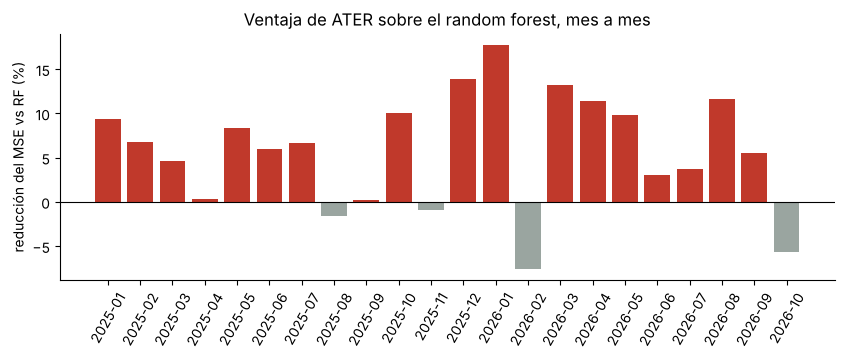

In [11]:
# ¿Dónde NO gana ATER? Error por mes y por segmento frente al random forest relativo
import pipeline_energia as P
pt = pd.read_pickle(R + "pred_prueba_con_original.pkl"); df = pd.read_pickle(R + "datos_horarios.pkl"); X, y = P.construir(df); Xt = X.loc[pt.index]
RF = "Random forest (relativo)"
mes = pt.groupby(pt.index.to_period("M")).apply(lambda d: 100 * (1 - np.mean((d.y - d[ORIG]) ** 2) / np.mean((d.y - d[RF]) ** 2)))
print("Meses en que ATER tiene menos MSE que el RF: %d de %d" % ((mes > 0).sum(), len(mes)))
seg = pd.DataFrame({"tipo de día": np.where(Xt.festivo == 1, "festivo", np.where(Xt.dow >= 5, "fin de semana", "laboral")),
                    "calor": pd.qcut(Xt.calor, 4, labels=["frío", "templado", "caluroso", "muy caluroso"]).astype(str)}, index=pt.index)
for c in seg:
    print(pt.groupby(seg[c]).apply(lambda d: pd.Series({"MAPE_ATER": 100 * np.mean(np.abs(d.y - d[ORIG]) / d.y), "MAPE_RF": 100 * np.mean(np.abs(d.y - d[RF]) / d.y), "horas": len(d)})).round(2), "\n")
fig, ax = plt.subplots(figsize=(10, 3.2)); ax.bar(mes.index.astype(str), mes.values, color=np.where(mes > 0, "#C0392B", "#9AA5A0"))
ax.axhline(0, color="k", lw=.8); ax.set_ylabel("reducción del MSE vs RF (%)"); ax.tick_params(axis="x", rotation=60); ax.set_title("Ventaja de ATER sobre el random forest, mes a mes"); plt.show()

**Dónde no gana.** ATER tiene menor MAPE que el random forest en todos los tipos de día y en los cuatro cuartiles de calor. La ventaja es mayor en los festivos (3,34 % frente a 3,72 %), donde la corrección de nivel en línea ayuda más, y casi nula en las horas frías (1,94 % frente a 1,97 %). Mes a mes pierde en 4 de 22 meses: la ventaja es pequeña y no es uniforme.

## Veredicto de superioridad (sección 6.1 de la guía)

In [12]:
ver = json.load(open(R + "orig_veredicto.json")); print(json.dumps(ver, indent=1, ensure_ascii=False))

{
 "mejor_benchmark": "Random forest (relativo)",
 "condicion1_metrica_media_mejor": true,
 "pruebas_que_rechazan_vs_mejor_benchmark": [
  "Diebold-Mariano (HLN)",
  "Giacomini-White condicional",
  "Wilcoxon de rangos con signo",
  "MCS (único sobreviviente)"
 ],
 "n_pruebas_rechazan": 4,
 "condicion2_tres_pruebas": true,
 "delta_cliff_pareado": 0.2526799387442573,
 "delta_cliff_no_pareado": 0.072782234896543,
 "d_cohen": 0.11913328798205511,
 "efecto_con_medidas_no_pareadas": "despreciable",
 "condicion3_efecto_no_despreciable": true,
 "R3": true,
 "mcs_incluidos": [
  "ATER (modelo original)"
 ],
 "ida_y_vuelta": true,
 "ida_y_vuelta_max_dif_MWh": 1.1368683772161603e-12,
 "hiperparametros": {
  "eta": 89.38423554574598,
  "lam": 0.9657109024109057,
  "sigma": 5.068873602673464,
  "eta_b": 0.00796538678948261
 }
}


**Veredicto.**

1. **Métrica media mejor que todos los benchmarks:** sí, en la validación anidada (MSE 2.097 ± 821 frente a 2.210 ± 759 del híbrido, el mejor benchmark ahí) y en la prueba (2.256 frente a 2.347 del random forest relativo).
2. **Al menos tres pruebas rechazan la igualdad con p ajustado < 0,05:** sí, frente a los 7 benchmarks. Frente al mejor (random forest relativo): Diebold-Mariano HLN p ajustado = 0,004, Giacomini-White p ajustado = 0,003, Wilcoxon p ajustado < 0,001, y el MCS deja a ATER como **único** modelo superior (p del RF = 0,005).
3. **Tamaño del efecto no despreciable:** frente a los tradicionales, Ridge y el híbrido el efecto es mediano o grande con cualquier medida. Frente a los árboles relativos es **pequeño**: el δ de Cliff **pareado** (mismo día) es 0,25 frente al RF y 0,22 frente al XGBoost (umbral 0,147), y ATER gana el 62,6 % y el 61,1 % de los días. Con el δ de Cliff **no pareado** (0,07) y la d de Cohen (0,12) el efecto sería despreciable. Como todas las pruebas son pareadas por día, la medida que corresponde es la pareada; se reportan las tres para que el lector juzgue.

**Conclusión:** ATER es **estadísticamente superior** a todos los benchmarks (R3), con una ventaja práctica grande frente a los métodos tradicionales (65 % menos MSE que la persistencia) y **pequeña pero consistente** frente a los mejores árboles (3,9 % menos MSE que el random forest relativo, IC 95 %: 1,1–6,8 %; entre 3,6 y 3,9 % en las 5 semillas probadas y en 18 de 22 meses).